## Objetivos del estudio:

El objetivo principal es evaluar si la implementación de un sistema de recomendaciones mejorado, la conversión de los usuarios de una tienda en línea internacional.

 La prueba A/B se denomina recommender_system_test y compara dos grupos:

- Grupo A (control): usuarios que pertenecen al grupo de control.

- Grupo B (experimental): usuarios expuestos a la nueva experiencia que se desea evaluar.

Se espera que el grupo B presente un aumento mínimo del 10 % en cada una de las siguientes etapas del embudo de conversión:

- Visualización de la página del producto (product_page).

- Adición de productos al carrito (product_cart).

- Compra (purchase).

## El análisis se centrará en los siguientes objetivos específicos:

- Explorar y preparar los conjuntos de datos para el análisis.

- Verificar la calidad de los datos y la correcta asignación de los participantes.

- Analizar la distribución temporal de los eventos y el comportamiento de los usuarios.

- Calcular y comparar las tasas de conversión de los grupos A y B.

- Aplicar pruebas Z para determinar si existen diferencias estadísticamente significativas entre las proporciones de conversión.

- Evaluar si la prueba cumple con las condiciones necesarias para obtener conclusiones confiables.

- Formular conclusiones y recomendaciones basadas en los resultados.

### 1.0 Importar librerías:

En este apartado se importan las librerías necesarias para realizar el análisis exploratorio de los datos, procesar los conjuntos de datos, generar visualizaciones y aplicar pruebas estadísticas. También se configuran algunas opciones para facilitar la presentación de la información durante el análisis.

In [3]:
# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# Configurar la visualización de gráficos
sns.set_theme(style="whitegrid")

# Mostrar todas las columnas de los DataFrames
pd.set_option('display.max_columns', None)

Se importaron las siguientes librerías y herramientas:
- Pandas (pd): permite cargar, organizar, manipular y analizar los datos mediante estructuras como los DataFrames.
- NumPy (np): facilita las operaciones numéricas y los cálculos matemáticos.
- Matplotlib (plt): permite crear gráficos para representar visualmente los datos.
- Seaborn (sns): facilita la creación de gráficos estadísticos con una presentación más clara.
- SciPy (stats): proporciona funciones para realizar pruebas estadísticas y analizar diferencias entre grupos.
- proportions_ztest: permite comparar estadísticamente las proporciones de dos o más grupos, por ejemplo, las tasas de conversión de una prueba A/B.
Además, se configuró Seaborn con el estilo whitegrid para mostrar gráficos con una cuadrícula de fondo, lo que facilita la interpretación de los valores. Finalmente, se indicó a Pandas que mostrara todas las columnas de los DataFrames, evitando que algunas quedaran ocultas durante la inspección.

Resultado esperado: las herramientas necesarias quedan disponibles para las siguientes etapas del análisis. En este apartado todavía no se realizan cálculos ni pruebas estadísticas.

### 2.0 Cargar los conjuntos de datos:

En este apartado se cargan los cuatro conjuntos de datos proporcionados para el proyecto de análisis de una prueba A/B. Cada archivo contiene información diferente que permitirá estudiar las campañas de marketing, los nuevos usuarios registrados, los eventos realizados por los usuarios y su participación en los grupos experimentales.

In [4]:

# Cargar los datos de marketing
marketing_events = pd.read_csv(
    'ab_project_marketing_events_us.csv'
)

# Cargar los datos de nuevos usuarios
new_users = pd.read_csv(
    'final_ab_new_users_upd_us.csv'
)

# Cargar los eventos de los usuarios
events = pd.read_csv(
    'final_ab_events_upd_us.csv'
)

# Cargar los participantes de las pruebas A/B
participants = pd.read_csv(
    'final_ab_participants_upd_us.csv'
)


Se utilizó la función pd.read_csv() de Pandas para leer cada archivo CSV y almacenarlo en una variable independiente.

Los conjuntos de datos cargados son los siguientes:
- marketing_events: contiene información sobre los eventos y las campañas de marketing programados, que permite conocer las actividades promocionales relacionadas con el periodo de estudio.
- new_users: contiene información sobre los nuevos usuarios registrados, como sus fechas de registro, regiones y dispositivos, de acuerdo con las columnas disponibles.
- events: contiene los registros de los eventos realizados por los usuarios, incluyendo información temporal y el tipo de evento.
- participants: contiene información sobre los participantes de las pruebas A/B, como su identificador y el grupo experimental al que fueron asignados.
Cada archivo se almacenó en un DataFrame diferente para facilitar su consulta y análisis posterior.

Resultado esperado: los cuatro conjuntos de datos quedan cargados en memoria y disponibles para revisar su estructura, identificar posibles problemas de calidad y preparar la información para el análisis estadístico.

### 3.0 Inspección inicial:

En esta etapa se realiza una inspección inicial de las dimensiones de cada conjunto de datos. El objetivo es conocer cuántas filas y columnas contiene cada archivo, lo que permite identificar el volumen de información disponible y comprobar que los datos se hayan cargado correctamente.

In [5]:
# Revisar las dimensiones de los conjuntos de datos
print("Dimensiones de marketing:", marketing_events.shape)
print("Dimensiones de nuevos usuarios:", new_users.shape)
print("Dimensiones de eventos:", events.shape)
print("Dimensiones de participantes:", participants.shape)

Dimensiones de marketing: (14, 4)
Dimensiones de nuevos usuarios: (58703, 4)
Dimensiones de eventos: (423761, 4)
Dimensiones de participantes: (14525, 3)


Se utilizó el atributo .shape para obtener las dimensiones de cada DataFrame. Este atributo devuelve una tupla con dos valores:
- Primer valor: número de filas o registros.
- Segundo valor: número de columnas o variables.

Mediante las instrucciones print() se mostraron las dimensiones de los cuatro conjuntos de datos, acompañadas de etiquetas que permiten identificar fácilmente cada resultado.

Esta revisión permite conocer el tamaño de la información disponible para el análisis. Por ejemplo, un conjunto con muchas filas de eventos puede contener múltiples registros correspondientes a un mismo usuario, mientras que el archivo de participantes puede tener una estructura más reducida.

Resultado esperado: se obtiene el número de registros y variables de cada archivo. Estos resultados servirán como referencia para comprobar posteriormente si los datos se modifican durante la limpieza y el procesamiento.

### 4.0 Revisar las primeras filas: 

En este apartado se muestran las primeras cinco filas de cada conjunto de datos para conocer su contenido y la forma en que está organizada la información. Esta inspección visual permite identificar los nombres de las columnas, observar ejemplos de registros y detectar posibles inconsistencias iniciales.

In [6]:
# Mostrar las primeras filas de cada conjunto de datos
display(marketing_events.head())
display(new_users.head())
display(events.head())
display(participants.head())

,name,regions,start_dt,finish_dt
0,Christmas&New Year Promo,"EU, N.America",2020-12-25,2021-01-03
1,St. Valentine's Day Giveaway,"EU, CIS, APAC, N.America",2020-02-14,2020-02-16
2,St. Patric's Day Promo,"EU, N.America",2020-03-17,2020-03-19
3,Easter Promo,"EU, CIS, APAC, N.America",2020-04-12,2020-04-19
4,4th of July Promo,N.America,2020-07-04,2020-07-11


,user_id,first_date,region,device
0,D72A72121175D8BE,2020-12-07,EU,PC
1,F1C668619DFE6E65,2020-12-07,N.America,Android
2,2E1BF1D4C37EA01F,2020-12-07,EU,PC
3,50734A22C0C63768,2020-12-07,EU,iPhone
4,E1BDDCE0DAFA2679,2020-12-07,N.America,iPhone


,user_id,event_dt,event_name,details
0,E1BDDCE0DAFA2679,2020-12-07 20:22:03,purchase,99.99
1,7B6452F081F49504,2020-12-07 09:22:53,purchase,9.99
2,9CD9F34546DF254C,2020-12-07 12:59:29,purchase,4.99
3,96F27A054B191457,2020-12-07 04:02:40,purchase,4.99
4,1FD7660FDF94CA1F,2020-12-07 10:15:09,purchase,4.99


,user_id,group,ab_test
0,D1ABA3E2887B6A73,A,recommender_system_test
1,A7A3664BD6242119,A,recommender_system_test
2,DABC14FDDFADD29E,A,recommender_system_test
3,04988C5DF189632E,A,recommender_system_test
4,4FF2998A348C484F,A,recommender_system_test


Se utilizó el método .head() para consultar las primeras cinco filas de cada DataFrame. La función display() permite presentar cada resultado de manera estructurada dentro de Jupyter Notebook.

La inspección de las tablas permite:
- Identificar los nombres y el tipo de información que contiene cada columna.
- Observar ejemplos de registros para comprender la estructura de los datos.
- Reconocer posibles diferencias en los formatos de fechas, identificadores y categorías.
- Detectar visualmente valores vacíos, nombres de columnas poco claros o datos que requieran una revisión adicional.

Se revisaron los cuatro conjuntos de datos por separado para comprender su contenido antes de continuar con el análisis.

Resultado esperado: se obtiene una vista preliminar de la información que ayudará a determinar qué variables son relevantes y qué aspectos deben verificarse durante la limpieza de los datos.

Nota: mostrar las primeras filas no garantiza que todos los registros estén correctos. Por ello, esta inspección debe complementarse con la revisión de los tipos de datos, los valores ausentes y los posibles duplicados.

### 5.0. Revisar los tipos de datos y valores ausentes:

En esta etapa se examina la estructura general de cada conjunto de datos para conocer los nombres de las columnas, la cantidad de registros no nulos y los tipos de datos asignados a cada variable. Esta revisión es importante para identificar posibles valores ausentes y determinar si algunas columnas necesitan transformaciones antes del análisis.

In [7]:
# Revisar la estructura general de cada conjunto de datos
print("DATOS DE MARKETING")
marketing_events.info()

print("\nNUEVOS USUARIOS")
new_users.info()

print("\nEVENTOS")
events.info()

print("\nPARTICIPANTES")
participants.info()

DATOS DE MARKETING
<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   name       14 non-null     str  
 1   regions    14 non-null     str  
 2   start_dt   14 non-null     str  
 3   finish_dt  14 non-null     str  
dtypes: str(4)
memory usage: 580.0 bytes

NUEVOS USUARIOS
<class 'pandas.DataFrame'>
RangeIndex: 58703 entries, 0 to 58702
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     58703 non-null  str  
 1   first_date  58703 non-null  str  
 2   region      58703 non-null  str  
 3   device      58703 non-null  str  
dtypes: str(4)
memory usage: 1.8 MB

EVENTOS
<class 'pandas.DataFrame'>
RangeIndex: 423761 entries, 0 to 423760
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   user_id     423761 non-null  str    
 1 

Se utilizó el método .info() para obtener un resumen de la estructura de cada DataFrame. La información que proporciona incluye:
- Número de entradas: cantidad total de filas del conjunto de datos.
- Nombres de las columnas: variables disponibles para el análisis.
- Cantidad de valores no nulos: número de registros que contienen información en cada columna.
- Tipos de datos (Dtype): indica si las variables están almacenadas como números enteros, decimales, texto, fechas u otros tipos.
- Uso de memoria: proporciona una referencia del espacio que ocupa cada DataFrame en memoria.
Los mensajes impresos antes de cada consulta permiten distinguir fácilmente los resultados de los cuatro conjuntos de datos.

Esta revisión ayuda a identificar columnas con posibles valores ausentes y variables que podrían requerir conversiones de tipo. Por ejemplo, las fechas que estén almacenadas como texto podrían necesitar convertirse al formato datetime para facilitar el análisis temporal.
El método .info() muestra cuántos valores no nulos existen en cada columna, pero no identifica por sí solo todas las inconsistencias ni determina qué tratamiento debe darse a los valores ausentes. Es necesario revisar los resultados obtenidos antes de decidir si se deben convertir variables, completar valores o eliminar registros.

Resultado esperado: se obtiene un resumen estructural de cada conjunto de datos que servirá para planificar las siguientes tareas de preparación y limpieza.

### 5.1. Conversión de tipos de datos:

En esta etapa se revisarán y convertirán las columnas que representan fechas para facilitar el análisis temporal. También se comprobará si existen valores ausentes y registros duplicados.

La columna details del conjunto de eventos se conservará inicialmente, ya que sus valores ausentes pueden ser normales para eventos que no contienen información monetaria.

In [8]:
# Convertir las fechas del calendario de marketing
marketing_events['start_dt'] = pd.to_datetime(
    marketing_events['start_dt'],
    errors='coerce'
)

marketing_events['finish_dt'] = pd.to_datetime(
    marketing_events['finish_dt'],
    errors='coerce'
)

# Convertir la fecha de registro de los usuarios
new_users['first_date'] = pd.to_datetime(
    new_users['first_date'],
    errors='coerce'
)

# Convertir la fecha y hora de los eventos
events['event_dt'] = pd.to_datetime(
    events['event_dt'],
    errors='coerce'
)

# Comprobar los tipos de datos después de la conversión
print("Tipos de datos de marketing:")
display(marketing_events.dtypes)

print("Tipos de datos de nuevos usuarios:")
display(new_users.dtypes)

print("Tipos de datos de eventos:")
display(events.dtypes)

Tipos de datos de marketing:


name                    str
regions                 str
start_dt     datetime64[us]
finish_dt    datetime64[us]
dtype: object

Tipos de datos de nuevos usuarios:


user_id                  str
first_date    datetime64[us]
region                   str
device                   str
dtype: object

Tipos de datos de eventos:


user_id                  str
event_dt      datetime64[us]
event_name               str
details              float64
dtype: object

En este apartado se utilizó la función pd.to_datetime() para transformar las columnas de fechas en un formato que Pandas pueda reconocer y procesar como información temporal.

Se realizaron las siguientes conversiones:
- marketing_events['start_dt']: convierte la fecha de inicio de los eventos de marketing.
- marketing_events['finish_dt']: convierte la fecha de finalización de los eventos de marketing.
- new_users['first_date']: convierte la fecha en que se registró cada usuario.
- events['event_dt']: convierte la fecha y hora en que ocurrió cada evento registrado por los usuarios.
En las cuatro conversiones se utilizó el parámetro errors='coerce'. Esto significa que, si algún valor no puede convertirse correctamente, Pandas lo reemplaza por NaT (Not a Time), que representa un valor temporal ausente o no válido.

Posteriormente, se utilizó el atributo .dtypes para consultar los tipos de datos de las columnas de los conjuntos de marketing, nuevos usuarios y eventos. La función display() permite visualizar esta información de manera organizada en Jupyter Notebook.

Esta comprobación permite verificar si las columnas de fechas se convirtieron correctamente, normalmente al tipo datetime64[ns] cuando no tienen zona horaria.

Resultado esperado: las columnas temporales quedan preparadas para realizar análisis por fechas, ordenar eventos cronológicamente, establecer periodos de registro y estudiar el comportamiento de los usuarios durante la prueba A/B.

Nota importante: la conversión de fechas no elimina registros ni corrige automáticamente las fechas incorrectas. Si algún valor se transforma en NaT, será necesario identificarlo y evaluar su tratamiento en las siguientes etapas de limpieza.

### 5.2. Identificación de valores ausentes:

Se calculará la cantidad y el porcentaje de valores ausentes en cada conjunto de datos. Esto permitirá distinguir los campos incompletos que requieren revisión de aquellos cuya ausencia puede estar justificada por la naturaleza del evento.

In [9]:
# Revisar los valores ausentes en cada conjunto de datos
datasets = {
    'Marketing': marketing_events,
    'Nuevos usuarios': new_users,
    'Eventos': events,
    'Participantes': participants
}

for nombre, df in datasets.items():
    print(f"\n{nombre}")

    missing = pd.DataFrame({
        'Valores ausentes': df.isna().sum(),
        'Porcentaje (%)': (df.isna().mean() * 100).round(2)
    })

    display(missing[missing['Valores ausentes'] > 0])


Marketing


,Valores ausentes,Porcentaje (%)



Nuevos usuarios


,Valores ausentes,Porcentaje (%)



Eventos


,Valores ausentes,Porcentaje (%)
details,363447,85.77



Participantes


,Valores ausentes,Porcentaje (%)


Se creó un diccionario llamado datasets para agrupar los cuatro DataFrames bajo nombres descriptivos. Esto permite aplicar la misma revisión a todos los conjuntos de datos sin repetir el código para cada uno.

Posteriormente, se utilizó un ciclo for para recorrer cada conjunto de datos y ejecutar las siguientes operaciones:
- df.isna().sum(): cuenta cuántos valores ausentes existen en cada columna.
- df.isna().mean() * 100: calcula el porcentaje de valores ausentes respecto al total de registros de cada columna.
- .round(2): redondea los porcentajes a dos decimales para facilitar su lectura.
- pd.DataFrame(): organiza los resultados en una tabla con las columnas Valores ausentes y Porcentaje (%).
- missing[missing['Valores ausentes'] > 0]: filtra la tabla para mostrar únicamente las columnas que contienen valores ausentes.
- display(): presenta los resultados de manera estructurada en Jupyter Notebook.
Además, se utilizó print() para identificar a qué conjunto de datos pertenece cada tabla de resultados.
Interpretación de los resultados
La salida de este código permite conocer qué columnas necesitan una revisión adicional y qué tan significativo es el porcentaje de información faltante en cada una.
- Si aparece una tabla con columnas, significa que ese conjunto de datos contiene valores ausentes.
- Si aparece una tabla vacía, significa que no se encontraron valores ausentes en las columnas de ese conjunto de datos.
- Un porcentaje elevado de valores ausentes puede afectar determinados análisis, dependiendo de la variable y de la importancia de la información faltante.
Resultado esperado: obtener un diagnóstico inicial de los valores ausentes en los cuatro conjuntos de datos para decidir qué tratamiento, si alguno, es adecuado antes de realizar el análisis estadístico.

Importante: este código únicamente identifica y cuantifica los valores ausentes; no los elimina ni los reemplaza. Además, los valores convertidos a NaT durante la transformación de fechas del apartado anterior también se contabilizarán como ausentes. La decisión de eliminarlos o tratarlos debe tomarse después de examinar los resultados y su relevancia para el experimento A/B.

### 5.3. Identificación de registros duplicados:

Se revisará la existencia de filas completamente duplicadas en cada conjunto de datos. Además, se comprobará si existen identificadores de usuario repetidos en las tablas donde se espera que cada usuario tenga un único registro.

Es importante distinguir entre duplicados completos y usuarios repetidos legítimamente en los eventos, ya que una misma persona puede realizar varias acciones durante el periodo de observación.

In [10]:
# Revisar filas completamente duplicadas
for nombre, df in datasets.items():
    print(
        f"{nombre}: {df.duplicated().sum()} "
        "filas duplicadas"
    )

# Revisar identificadores de usuario repetidos
print(
    "\nUsuarios repetidos en nuevos usuarios:",
    new_users['user_id'].duplicated().sum()
)

print(
    "Usuarios repetidos en participantes:",
    participants['user_id'].duplicated().sum()
)

Marketing: 0 filas duplicadas
Nuevos usuarios: 0 filas duplicadas
Eventos: 0 filas duplicadas
Participantes: 0 filas duplicadas

Usuarios repetidos en nuevos usuarios: 0
Usuarios repetidos en participantes: 887


Primero, se utilizó un ciclo for para recorrer los cuatro conjuntos de datos almacenados en el diccionario datasets. En cada uno se aplicó el método .duplicated().sum() para contar las filas que están completamente duplicadas.

Después, se revisaron los identificadores de usuario (user_id) en los conjuntos new_users y participants, con el propósito de identificar usuarios que aparecen más de una vez en cada tabla.

Las principales instrucciones utilizadas fueron:
- df.duplicated(): identifica las filas cuyos valores coinciden con los de una fila anterior en todas las columnas.
- .sum(): cuenta cuántas filas fueron identificadas como duplicadas.
- new_users['user_id'].duplicated().sum(): cuenta las apariciones repetidas de identificadores de usuario en la tabla de nuevos usuarios.
- participants['user_id'].duplicated().sum(): cuenta las apariciones repetidas de identificadores de usuario en la tabla de participantes.
- print(): muestra los resultados con etiquetas que facilitan su interpretación.
Es importante distinguir entre las filas completamente duplicadas y los identificadores repetidos. Dos filas pueden tener el mismo user_id y diferir en otras columnas, por lo que no necesariamente son duplicados exactos.
Interpretación de los resultados
Los resultados permiten identificar posibles problemas de duplicación y evaluar si es necesario realizar una revisión adicional.
- Cero filas duplicadas: no se encontraron registros completamente idénticos en ese conjunto de datos.
- Una o más filas duplicadas: existen registros idénticos que conviene revisar antes de decidir si deben eliminarse.
- Cero usuarios repetidos: cada identificador aparece una sola vez en la tabla revisada.
- Usuarios repetidos: es necesario comprobar si se trata de registros indebidos o de una situación válida según la estructura del conjunto de datos.
En particular, en la tabla participants, un usuario repetido podría estar relacionado con su asignación a grupos experimentales diferentes. Por eso, conviene revisar esa situación antes de eliminar registros, ya que podría afectar la interpretación de la prueba A/B.

Resultado esperado: conocer la cantidad de filas completamente duplicadas y de identificadores de usuario repetidos en las tablas seleccionadas, para determinar si se requiere una limpieza adicional.

Importante: este código solo identifica y cuenta duplicados; no elimina ninguna fila. Las decisiones de limpieza deben tomarse después de revisar los resultados y comprobar la consistencia de los datos.

### 6.0. Validación de la prueba A/B:

### 6.1. Revisión de los grupos experimentales:

Se verificará cuántos participantes pertenecen a cada grupo y cuántos registros corresponden a la prueba recommender_system_test.

También se comprobará si algún usuario aparece en ambos grupos, ya que compartir grupos puede comprometer la independencia de las muestras y afectar la interpretación de los resultados.

In [11]:
# Filtrar los participantes de la prueba de recomendaciones
test_participants = participants[
    participants['ab_test'] == 'recommender_system_test'
].copy()

# Revisar la cantidad de participantes por grupo
display(
    test_participants.groupby('group')['user_id']
    .nunique()
    .reset_index(name='usuarios')
)

# Revisar la cantidad de registros por prueba
display(
    participants.groupby('ab_test')['user_id']
    .nunique()
    .reset_index(name='usuarios')
)

# Comprobar si hay usuarios en ambos grupos de esta prueba
groups_per_user = test_participants.groupby(
    'user_id'
)['group'].nunique()

users_in_both_groups = groups_per_user[
    groups_per_user > 1
]

print(
    "Usuarios presentes en ambos grupos de la prueba:",
    len(users_in_both_groups)
)

,group,usuarios
0,A,2747
1,B,928


,ab_test,usuarios
0,interface_eu_test,10850
1,recommender_system_test,3675


Usuarios presentes en ambos grupos de la prueba: 0


Se filtraron los participantes correspondientes a la prueba recommender_system_test y se utilizó .copy() para trabajar con una copia independiente de los datos seleccionados.

Después, se contó la cantidad de usuarios únicos por grupo y por prueba A/B. Finalmente, se verificó si algún usuario estaba asignado a más de un grupo dentro de la prueba seleccionada.

Objetivo: comprobar la distribución de los participantes y detectar posibles asignaciones inconsistentes que puedan afectar la validez de los resultados del experimento.

### 6.2. Comprobación de usuarios compartidos entre pruebas:

Se revisará si algunos usuarios participaron tanto en recommender_system_test como en interface_eu_test. La participación simultánea en diferentes experimentos podría influir en el comportamiento de los usuarios y dificultar la interpretación de los resultados.

También se comprobará la distribución de los participantes por región y fecha de registro para verificar si corresponden a la audiencia definida en las especificaciones técnicas.

In [12]:
# Identificar usuarios que aparecen en ambas pruebas
users_recommender = set(
    participants.loc[
        participants['ab_test'] == 'recommender_system_test',
        'user_id'
    ]
)

users_interface = set(
    participants.loc[
        participants['ab_test'] == 'interface_eu_test',
        'user_id'
    ]
)

shared_users = users_recommender.intersection(users_interface)

print("Usuarios en ambas pruebas:", len(shared_users))

# Revisar la región y la fecha de registro de los participantes
recommender_users = test_participants.merge(
    new_users,
    on='user_id',
    how='left',
    validate='one_to_one'
)

print("Participantes sin datos de registro:")
print(recommender_users['first_date'].isna().sum())

print("\nDistribución por región:")
display(
    recommender_users['region']
    .value_counts(dropna=False)
    .rename_axis('region')
    .reset_index(name='usuarios')
)

print("\nDistribución por dispositivo:")
display(
    recommender_users['device']
    .value_counts(dropna=False)
    .rename_axis('device')
    .reset_index(name='usuarios')
)

print("\nFechas de registro:")
print("Primera fecha:", recommender_users['first_date'].min())
print("Última fecha:", recommender_users['first_date'].max())

Usuarios en ambas pruebas: 887
Participantes sin datos de registro:
0

Distribución por región:


,region,usuarios
0,EU,3481
1,N.America,119
2,APAC,45
3,CIS,30



Distribución por dispositivo:


,device,usuarios
0,Android,1625
1,PC,953
2,iPhone,751
3,Mac,346



Fechas de registro:
Primera fecha: 2020-12-07 00:00:00
Última fecha: 2020-12-21 00:00:00


Se identificaron los usuarios que participaron en ambas pruebas A/B mediante conjuntos (set) y la operación intersection(). Después, se combinaron los participantes de la prueba de recomendaciones con los datos de nuevos usuarios mediante merge() para revisar su información de registro.

Finalmente, se verificaron los registros sin fecha de registro, la distribución de los participantes por región y dispositivo, y las fechas mínima y máxima de registro.

Objetivo: detectar usuarios compartidos entre experimentos, comprobar la integridad de los datos de registro y conocer las características de los participantes antes de continuar con el análisis.

### 6.3. Análisis del periodo de observación:

La prueba comenzó el 7 de diciembre de 2020 y dejó de aceptar nuevos usuarios el 21 de diciembre de 2020. Los eventos se recopilaron hasta el 1 de enero de 2021.

Se analizará la distribución de los eventos en el tiempo y se verificará si los usuarios tuvieron la oportunidad de completar los 14 días de seguimiento establecidos en el experimento.

Esta revisión es importante porque los usuarios registrados cerca del final del periodo de incorporación podrían tener una ventana de observación incompleta.

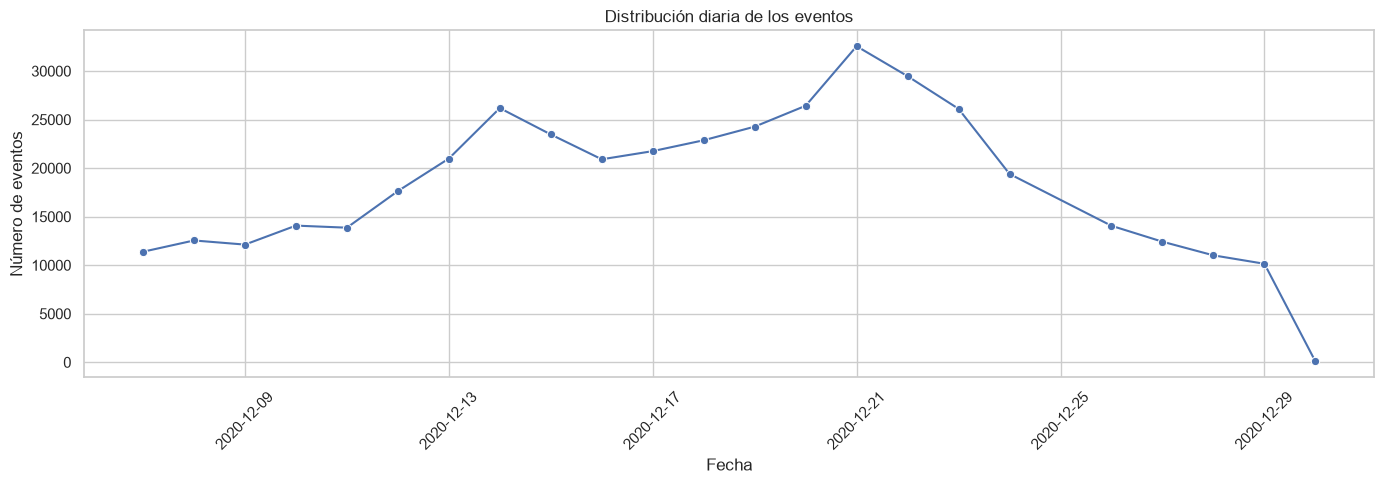

,event_date,event_count
0,2020-12-07,11385
1,2020-12-08,12547
2,2020-12-09,12122
3,2020-12-10,14077
4,2020-12-11,13864
5,2020-12-12,17634
6,2020-12-13,20985
7,2020-12-14,26184
8,2020-12-15,23469
9,2020-12-16,20909


In [13]:

# Importar las librerías necesarias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los eventos de los usuarios
events = pd.read_csv('final_ab_events_upd_us.csv')

# Convertir la columna event_dt a formato de fecha y hora
events['event_dt'] = pd.to_datetime(events['event_dt'])

# Calcular el número de eventos por día
events['event_date'] = events['event_dt'].dt.date

daily_events = (
    events.groupby('event_date')
    .size()
    .reset_index(name='event_count')
)

# Visualizar la distribución diaria
plt.figure(figsize=(14, 5))

sns.lineplot(
    data=daily_events,
    x='event_date',
    y='event_count',
    marker='o'
)

plt.title('Distribución diaria de los eventos')
plt.xlabel('Fecha')
plt.ylabel('Número de eventos')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Mostrar la tabla con el número de eventos por día
display(daily_events)


Se creó la columna event_date para extraer la fecha de cada evento y se agruparon los registros por día para calcular el número de eventos diarios. Después, se utilizó Seaborn y Matplotlib para generar un gráfico de líneas que permite visualizar cómo cambia la actividad a lo largo del tiempo. Finalmente, se mostró una tabla con los conteos diarios.

Objetivo: identificar variaciones en la actividad de los usuarios y detectar posibles días con aumentos o disminuciones importantes en el número de eventos.

### 6.3.1. Revisar los tipos de eventos:

,event_name,event_count
0,login,182465
1,product_page,120862
2,purchase,60314
3,product_cart,60120


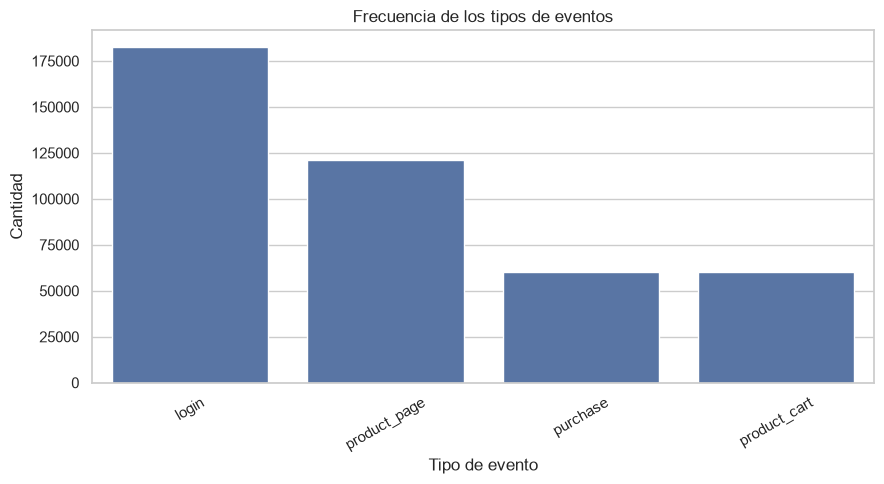

In [14]:
# Revisar la frecuencia de cada tipo de evento
event_counts = (
    events['event_name']
    .value_counts()
    .rename_axis('event_name')
    .reset_index(name='event_count')
)

display(event_counts)

# Visualizar la cantidad de eventos por tipo
plt.figure(figsize=(9, 5))

sns.barplot(
    data=event_counts,
    x='event_name',
    y='event_count'
)

plt.title('Frecuencia de los tipos de eventos')
plt.xlabel('Tipo de evento')
plt.ylabel('Cantidad')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Se utilizó value_counts() para contar la frecuencia de cada tipo de evento registrado en la columna event_name. Los resultados se organizaron en una tabla y posteriormente se representaron mediante un gráfico de barras para comparar visualmente la cantidad de eventos por categoría.

Objetivo: identificar los tipos de eventos más frecuentes y comprender qué acciones realizan los usuarios con mayor frecuencia, como parte de la exploración inicial de los datos.

### 7.0. Análisis del embudo de conversión:

Se analizará cuántos usuarios únicos realizaron cada tipo de evento en los grupos A y B.

El embudo estará compuesto por las siguientes etapas:

- product_page: visualización de la página del producto.

- product_cart: adición de productos al carrito.

- purchase: compra.

Se calcularán las proporciones de usuarios que alcanzaron cada etapa con respecto al total de usuarios de su grupo. También se examinará el número de eventos por usuario para identificar diferencias de actividad entre las muestras.

Antes de comparar los resultados, se verificará la ventana de observación y se limitará el análisis a los participantes de la prueba correspondiente.

In [18]:

# Importar pandas si todavía no está importado
import pandas as pd

# Asegurar que las columnas tengan formato de fecha
events['event_dt'] = pd.to_datetime(events['event_dt'])
new_users['first_date'] = pd.to_datetime(new_users['first_date'])

# Conservar únicamente los eventos de los usuarios de la prueba
test_events = events[
    events['user_id'].isin(users_recommender)
].copy()

# Añadir el grupo asignado a cada usuario
test_events = test_events.merge(
    test_participants[['user_id', 'group']],
    on='user_id',
    how='inner',
    validate='many_to_one'
)

# Añadir la fecha de registro
test_events = test_events.merge(
    new_users[['user_id', 'first_date']],
    on='user_id',
    how='left',
    validate='many_to_one'
)

# Crear la fecha del evento
test_events['event_date'] = test_events['event_dt'].dt.date

# Calcular los días transcurridos desde el registro
test_events['days_since_registration'] = (
    test_events['event_dt'].dt.normalize()
    - test_events['first_date'].dt.normalize()
).dt.days

# Organizar las columnas para facilitar la lectura
columnas = [
    'user_id',
    'event_dt',
    'event_name',
    'details',
    'event_date',
    'group',
    'first_date',
    'days_since_registration'
]

# Mostrar resultados de validación
print("Eventos de participantes:", test_events.shape)

print("\nEventos sin fecha de registro:")
print(test_events['first_date'].isna().sum())

print("\nEventos anteriores al registro:")
print((test_events['days_since_registration'] < 0).sum())

# Mostrar la tabla con las columnas ordenadas
display(test_events[columnas].head(10))


Eventos de participantes: (23909, 8)

Eventos sin fecha de registro:
0

Eventos anteriores al registro:
0


,user_id,event_dt,event_name,details,event_date,group,first_date,days_since_registration
0,831887FE7F2D6CBA,2020-12-07 06:50:29,purchase,4.99,2020-12-07,A,2020-12-07,0
1,3C5DD0288AC4FE23,2020-12-07 19:42:40,purchase,4.99,2020-12-07,A,2020-12-07,0
2,49EA242586C87836,2020-12-07 06:31:24,purchase,99.99,2020-12-07,B,2020-12-07,0
3,2B06EB547B7AAD08,2020-12-07 21:36:38,purchase,4.99,2020-12-07,A,2020-12-07,0
4,A640F31CAC7823A6,2020-12-07 18:48:26,purchase,4.99,2020-12-07,B,2020-12-07,0
5,2F46396B6766CFDB,2020-12-07 13:29:30,purchase,4.99,2020-12-07,A,2020-12-07,0
6,538F954F6B3AECE4,2020-12-07 07:12:05,purchase,4.99,2020-12-07,A,2020-12-07,0
7,A9908F62C41613A8,2020-12-07 11:26:47,purchase,9.99,2020-12-07,B,2020-12-07,0
8,0997EC1C4850B27B,2020-12-07 08:01:55,purchase,4.99,2020-12-07,B,2020-12-07,0
9,C7CB2F1BA42F102B,2020-12-07 03:05:05,purchase,99.99,2020-12-07,B,2020-12-07,0


Se filtraron los eventos correspondientes a los usuarios de la prueba de recomendaciones y se incorporó el grupo experimental asignado a cada participante. Después, se añadieron las fechas de registro y se calculó cuántos días transcurrieron entre el registro de cada usuario y la realización de sus eventos.

Finalmente, se revisó la cantidad de registros obtenidos, los eventos sin fecha de registro y aquellos que aparentemente ocurrieron antes del registro del usuario. También se mostraron las primeras filas para verificar la información integrada.

Objetivo: preparar los datos de los participantes para analizar su comportamiento durante el experimento y detectar posibles inconsistencias en las fechas.

### 7.1. Revisar los eventos dentro de los 14 días: 

En este apartado se filtran los eventos ocurridos durante los primeros 14 días desde el registro de cada usuario, incluyendo el día de registro. También se verifica si todos los participantes tuvieron una ventana de observación completa para evaluar su comportamiento durante el mismo periodo.

In [23]:
# Conservar los eventos ocurridos entre el registro
# y los 14 días siguientes, incluyendo el día de registro
test_events_14d = test_events[
    test_events['days_since_registration'].between(0, 13)
].copy()

print("Eventos originales de los participantes:", len(test_events))
print("Eventos dentro de los primeros 14 días:", len(test_events_14d))

# Revisar cuántos participantes tienen una ventana
# completa de 14 días hasta el 1 de enero de 2021
observation_end = pd.Timestamp('2021-01-01')

recommender_users['observation_days'] = (
    observation_end - recommender_users['first_date']
).dt.days

print(
    "Participantes con menos de 14 días disponibles:",
    (recommender_users['observation_days'] < 14).sum()
)

Eventos originales de los participantes: 23909
Eventos dentro de los primeros 14 días: 23151
Participantes con menos de 14 días disponibles: 1133


Se filtraron los eventos registrados entre el día 0 y el día 13 desde el registro, formando una ventana de 14 días. Después, se comparó la cantidad de eventos originales con los que cumplen este criterio y se calculó el tiempo disponible de observación de cada participante hasta el 1 de enero de 2021.

Objetivo: estandarizar el periodo de análisis y comprobar si los participantes contaron con suficiente tiempo de observación para evaluar sus eventos durante los primeros 14 días.

### 7.2. Verificación de la cobertura temporal: 

Antes de calcular las tasas de conversión, se revisará la cobertura temporal del conjunto de eventos. Esta comprobación permitirá identificar fechas sin registros y determinar si los datos cubren adecuadamente el periodo previsto para la prueba.

In [24]:
# Revisar el intervalo temporal de los eventos
print("Primer evento:", events['event_dt'].min())
print("Último evento:", events['event_dt'].max())

# Crear un calendario completo para identificar fechas sin registros
daily_events = (
    events.groupby(events['event_dt'].dt.normalize())
    .size()
    .rename('event_count')
)

calendar = pd.date_range(
    start=events['event_dt'].min().normalize(),
    end=events['event_dt'].max().normalize(),
    freq='D'
)

daily_events = daily_events.reindex(calendar, fill_value=0)
daily_events.index.name = 'event_date'

print("\nFechas sin eventos dentro del intervalo disponible:")
display(
    daily_events[daily_events == 0]
    .rename_axis('event_date')
    .reset_index()
)

Primer evento: 2020-12-07 00:00:33
Último evento: 2020-12-30 23:36:33

Fechas sin eventos dentro del intervalo disponible:


,event_date,event_count
0,2020-12-25,0


Se identificaron la fecha del primer y último evento registrado para conocer el intervalo temporal de los datos. Después, se agruparon los eventos por día y se creó un calendario continuo que incluye todas las fechas comprendidas entre ambos extremos. Mediante reindex() se asignó un valor de cero a los días sin registros y, finalmente, se mostraron las fechas en las que no se registraron eventos.

Objetivo: comprobar la continuidad temporal de los datos e identificar posibles días sin actividad registrada durante el periodo analizado.

### 7.3. Selección de participantes para el análisis:

Se preparará una muestra de participantes de la prueba de recomendaciones que pertenezcan a la región europea y no estén incluidos simultáneamente en el experimento de interfaz. El objetivo es reducir posibles interferencias entre pruebas y trabajar con una población más acorde con las condiciones del experimento.

In [25]:
# Identificar usuarios que participan en ambas pruebas
users_recommender = set(
    participants.loc[
        participants['ab_test'] == 'recommender_system_test',
        'user_id'
    ]
)

users_interface = set(
    participants.loc[
        participants['ab_test'] == 'interface_eu_test',
        'user_id'
    ]
)

shared_users = users_recommender.intersection(users_interface)

# Obtener los participantes de la prueba de recomendaciones
test_participants = participants[
    participants['ab_test'] == 'recommender_system_test'
].copy()

# Añadir la información de registro, región y dispositivo
recommender_users = test_participants.merge(
    new_users,
    on='user_id',
    how='left',
    validate='one_to_one'
)

# Excluir usuarios compartidos y participantes fuera de la UE
valid_users = recommender_users[
    (~recommender_users['user_id'].isin(shared_users)) &
    (recommender_users['region'] == 'EU')
].copy()

print("Participantes originales:", len(recommender_users))
print("Usuarios compartidos entre pruebas:", len(shared_users))
print("Participantes de la UE sin solapamiento:", len(valid_users))

print("\nDistribución de los grupos en la muestra filtrada:")
display(
    valid_users['group']
    .value_counts()
    .rename_axis('group')
    .reset_index(name='users')
)

Participantes originales: 3675
Usuarios compartidos entre pruebas: 887
Participantes de la UE sin solapamiento: 2594

Distribución de los grupos en la muestra filtrada:


,group,users
0,A,1939
1,B,655


Se identificaron los usuarios que participan en ambas pruebas A/B y se seleccionaron los participantes de la prueba recommender_system_test. Después, se incorporó su información de registro, región y dispositivo, y se excluyeron los usuarios compartidos entre pruebas y aquellos que no pertenecen a la Unión Europea (UE).

Finalmente, se comparó la cantidad de participantes antes y después del filtrado y se mostró la distribución de usuarios por grupo experimental.

Objetivo: obtener una muestra más consistente para analizar los resultados de la prueba de recomendaciones, reduciendo posibles interferencias de otros experimentos y limitando el análisis a la región objetivo.

### 8.0. Análisis del embudo de conversión:

Ahora vamos a calcular cuántos usuarios de cada grupo llegaron a cada etapa del proceso de compra y qué porcentaje representa cada etapa.

Nota metodológica: como los datos terminan el 30 de diciembre y faltan eventos del día 25, los resultados serán preliminares. Algunos usuarios no tienen observación completa de 14 días, así que no debemos presentar todavía las conversiones como una medición definitiva del proyecto.

### 8.1. Preparación de eventos de la muestra filtrada:

En esta sección se analizarán los eventos de los participantes de la UE que pertenecen a la prueba de recomendaciones y no participaron simultáneamente en la prueba de interfaz. Se considerarán los eventos registrados durante los primeros 14 días desde la fecha de registro, utilizando la fecha disponible en el conjunto de datos.

In [26]:
# Preparar los eventos de los participantes seleccionados
valid_user_ids = valid_users['user_id'].unique()

funnel_events = events[
    events['user_id'].isin(valid_user_ids)
].copy()

# Añadir grupo y fecha de registro
funnel_events = funnel_events.merge(
    valid_users[['user_id', 'group', 'first_date']],
    on='user_id',
    how='inner',
    validate='many_to_one'
)

# Calcular los días transcurridos desde el registro
funnel_events['days_since_registration'] = (
    funnel_events['event_dt'].dt.normalize() -
    funnel_events['first_date']
).dt.days

# Conservar los eventos de los primeros 14 días calendario
funnel_events_14d = funnel_events[
    funnel_events['days_since_registration'].between(0, 13)
].copy()

print("Usuarios incluidos:", valid_users['user_id'].nunique())
print("Eventos de la muestra:", len(funnel_events))
print("Eventos en los primeros 14 días:", len(funnel_events_14d))

print("\nEventos por grupo:")
display(
    funnel_events_14d.groupby('group')
    .size()
    .rename('event_count')
    .reset_index()
)

Usuarios incluidos: 2594
Eventos de la muestra: 16959
Eventos en los primeros 14 días: 16415

Eventos por grupo:


,group,event_count
0,A,12928
1,B,3487


Se seleccionaron los eventos de los usuarios incluidos en la muestra filtrada y se incorporaron sus grupos experimentales y fechas de registro. Después, se calculó el tiempo transcurrido desde el registro y se conservaron únicamente los eventos ocurridos durante los primeros 14 días calendario.

Finalmente, se mostraron la cantidad de usuarios incluidos, los eventos totales y los eventos por grupo dentro del periodo seleccionado.

Objetivo: preparar los datos para analizar el embudo de conversión y comparar el comportamiento de los grupos experimentales bajo la misma ventana de observación.

### 8.2. Cálculo de las tasas de conversión:

Se calculará el número de usuarios únicos que realizaron cada evento de conversión: visita a la página del producto, incorporación del producto al carrito y compra. Se comparará cada etapa con el total de participantes de su grupo y también se calculará la conversión entre etapas consecutivas.

Se definieron las tres etapas del embudo de conversión: visualización de la página del producto (product_page), agregar al carrito (product_cart) y compra (purchase). Después, se contaron los usuarios únicos por etapa y grupo, y se calcularon los porcentajes de conversión respecto al total de participantes y entre etapas consecutivas.

Finalmente, se redondearon los resultados a dos decimales y se organizaron en una tabla comparativa.

Objetivo: evaluar el avance de los usuarios por el embudo de conversión y comparar el comportamiento de los grupos experimentales durante los primeros 14 días.



### 8.3. Visualización del embudo:

Se visualizará la cantidad de usuarios únicos que alcanzaron cada etapa de conversión en los grupos A y B. Esta comparación permitirá observar diferencias descriptivas entre ambos grupos antes de realizar las pruebas estadísticas.

In [27]:
# Identificar usuarios que participaron en ambas pruebas

users_recommender = set(
    participants.loc[
        participants['ab_test'] == 'recommender_system_test',
        'user_id'
    ]
)

users_interface = set(
    participants.loc[
        participants['ab_test'] == 'interface_eu_test',
        'user_id'
    ]
)

shared_users = users_recommender.intersection(users_interface)

print('Usuarios que participaron en ambas pruebas:', len(shared_users))

# Seleccionar participantes de la prueba del sistema de recomendación

test_participants = participants[
    participants['ab_test'] == 'recommender_system_test'
].copy()

# Incorporar la información de registro de los usuarios

recommender_users = test_participants.merge(
    new_users,
    on='user_id',
    how='left',
    validate='one_to_one'
)

# Excluir usuarios compartidos y seleccionar la región EU

valid_users = recommender_users[
    (~recommender_users['user_id'].isin(shared_users)) &
    (recommender_users['region'] == 'EU')
].copy()

# Determinar la fecha límite de los eventos disponibles

data_cutoff = events['event_dt'].max()

# Calcular el final del periodo de observación de 14 días

valid_users['observation_end'] = (
    valid_users['first_date'] + pd.Timedelta(days=14)
)

# Conservar usuarios cuyo periodo de observación está cubierto

complete_users = valid_users[
    valid_users['observation_end'] <= data_cutoff
].copy()

# Revisar los resultados

print('Usuarios válidos:', len(valid_users))
print('Usuarios con periodo completo:', len(complete_users))

display(
    complete_users['group']
    .value_counts()
    .reindex(['A', 'B'], fill_value=0)
    .rename('usuarios')
    .to_frame()
)


Usuarios que participaron en ambas pruebas: 887
Usuarios válidos: 2594
Usuarios con periodo completo: 1419


,usuarios
group,
A,969
B,450


### 9.0. Validación del periodo de observación:

Antes de realizar la comparación definitiva entre los grupos A y B, se identificarán los participantes que dispusieron de al menos 14 días de seguimiento dentro del periodo cubierto por los datos. Se utilizará la última fecha y hora disponible como límite de observación y se considerará una ventana de 14 días desde la fecha de registro de cada usuario.

In [30]:
# Identificar el último momento disponible en los datos
data_cutoff = events['event_dt'].max()

# Calcular cuándo termina la ventana de 14 días de cada usuario
valid_users = valid_users.copy()

valid_users['observation_end'] = (
    valid_users['first_date'] + pd.Timedelta(days=14)
)

# Conservar únicamente usuarios cuyo seguimiento de 14 días
# termina antes del último momento disponible en los datos
complete_users = valid_users[
    valid_users['observation_end'] <= data_cutoff
].copy()

print("Último momento disponible:", data_cutoff)
print("Usuarios antes del filtro:", len(valid_users))
print("Usuarios con 14 días disponibles:", len(complete_users))
print("Usuarios excluidos por seguimiento incompleto:",
      len(valid_users) - len(complete_users))

print("\nDistribución de los grupos:")
display(
    complete_users['group']
    .value_counts()
    .rename_axis('group')
    .reset_index(name='users')
)

Último momento disponible: 2020-12-30 23:36:33
Usuarios antes del filtro: 2594
Usuarios con 14 días disponibles: 1419
Usuarios excluidos por seguimiento incompleto: 1175

Distribución de los grupos:


,group,users
0,A,969
1,B,450


Se identificó la fecha y hora del último evento disponible y se calculó cuándo termina la ventana de observación de 14 días para cada usuario. Después, se conservaron únicamente los participantes cuyo seguimiento completo termina antes del límite temporal de los datos.

Finalmente, se comparó la cantidad de usuarios antes y después del filtro y se revisó la distribución de los participantes por grupo.

### 9.1. Comparación estadística entre los grupos A y B:

En este apartado se seleccionan los eventos de los usuarios que cuentan con un periodo de seguimiento completo de 14 días. Se incorpora la información de su grupo experimental y fecha de registro para conservar únicamente los eventos ocurridos dentro de esa ventana temporal.

In [31]:
# Seleccionar eventos de usuarios con seguimiento completo
complete_user_ids = complete_users['user_id'].unique()

complete_events = events[
    events['user_id'].isin(complete_user_ids)
].copy()

# Añadir grupo y fecha de registro
complete_events = complete_events.merge(
    complete_users[['user_id', 'group', 'first_date']],
    on='user_id',
    how='inner',
    validate='many_to_one'
)

# Aplicar una ventana exacta de 14 días desde el registro
complete_events_14d = complete_events[
    (complete_events['event_dt'] >= complete_events['first_date']) &
    (
        complete_events['event_dt'] <
        complete_events['first_date'] + pd.Timedelta(days=14)
    )
].copy()

print("Eventos de usuarios con seguimiento completo:",
      len(complete_events))
print("Eventos dentro de sus primeros 14 días:",
      len(complete_events_14d))

display(
    complete_events_14d['group']
    .value_counts()
    .rename_axis('group')
    .reset_index(name='event_count')
)

Eventos de usuarios con seguimiento completo: 9570
Eventos dentro de sus primeros 14 días: 9026


,group,event_count
0,A,6518
1,B,2508


Se obtuvieron los identificadores de los usuarios con seguimiento completo y se filtraron sus eventos. Después, se integraron los grupos experimentales y las fechas de registro mediante merge(), y se conservaron los eventos ocurridos desde el registro hasta antes de cumplir 14 días.

Finalmente, se contabilizaron los eventos antes y después del filtrado y se mostró su distribución por grupo.

### 9.2 Recalcular el embudo de conversión: 

Se calculará el número de usuarios únicos que realizaron cada uno de los eventos principales del embudo: visita a la página del producto, incorporación al carrito y compra. Las tasas de conversión se calcularán tomando como denominador el total de participantes de cada grupo con seguimiento disponible de 14 días.

Esta comparación permitirá identificar diferencias descriptivas entre los grupos A y B antes de evaluar su significación estadística.

In [32]:
# Definir las etapas de conversión
funnel_stages = ['product_page', 'product_cart', 'purchase']

# Calcular el número de participantes únicos por grupo
group_sizes = (
    complete_users.groupby('group')['user_id']
    .nunique()
    .reindex(['A', 'B'], fill_value=0)
)

# Contar los usuarios únicos que realizaron cada evento
stage_users = (
    complete_events_14d[
        complete_events_14d['event_name'].isin(funnel_stages)
    ]
    .groupby(['group', 'event_name'])['user_id']
    .nunique()
    .unstack(fill_value=0)
    .reindex(index=['A', 'B'], fill_value=0)
    .reindex(columns=funnel_stages, fill_value=0)
)

# Crear la tabla de resultados
funnel_result = pd.DataFrame({
    'group': group_sizes.index,
    'participants': group_sizes.values
})

# Calcular usuarios y tasas de conversión por etapa
for stage in funnel_stages:
    funnel_result[f'{stage}_users'] = (
        stage_users[stage].reindex(['A', 'B']).values
    )

    funnel_result[f'{stage}_conversion_pct'] = (
        funnel_result[f'{stage}_users']
        / funnel_result['participants'] * 100
    )

# Redondear los porcentajes a dos decimales
percentage_columns = [
    col for col in funnel_result.columns
    if col.endswith('_conversion_pct')
]

funnel_result[percentage_columns] = (
    funnel_result[percentage_columns].round(2)
)

# Mostrar la tabla final
display(funnel_result)

,group,participants,product_page_users,product_page_conversion_pct,product_cart_users,product_cart_conversion_pct,purchase_users,purchase_conversion_pct
0,A,969,623,64.29,300,30.96,286,29.51
1,B,450,253,56.22,125,27.78,124,27.56


El código recalcula el embudo de conversión para los grupos A y B utilizando únicamente a los participantes con seguimiento completo de 14 días.

Primero, se definen las tres etapas del embudo: página del producto (product_page), carrito de compra (product_cart) y compra (purchase). Después, se calcula el número de participantes únicos de cada grupo y se cuentan los usuarios que realizaron cada evento durante el periodo de observación.

Posteriormente, se crea una tabla con el total de participantes, los usuarios que llegaron a cada etapa y sus respectivas tasas de conversión, calculadas como porcentaje del total de participantes de cada grupo. Finalmente, los porcentajes se redondean a dos decimales y se muestra la tabla de resultados.

### 9.3. Repetir las pruebas Z:

En este apartado se realizan pruebas Z bilaterales para comparar las tasas de conversión de los grupos A y B en cada etapa del embudo, utilizando únicamente participantes con seguimiento completo de 14 días. Se aplica la corrección de Bonferroni para controlar el riesgo de falsos positivos al realizar varias comparaciones.

In [33]:
# Pruebas Z para comparar las tasas de conversión
alpha = 0.05
alpha_corrected = alpha / len(funnel_stages)

results = []

for stage in funnel_stages:
    count_a = int(stage_users.loc['A', stage])
    count_b = int(stage_users.loc['B', stage])

    n_a = int(group_sizes.loc['A'])
    n_b = int(group_sizes.loc['B'])

    z_stat, p_value = proportions_ztest(
        count=[count_a, count_b],
        nobs=[n_a, n_b],
        alternative='two-sided'
    )

    rate_a = count_a / n_a
    rate_b = count_b / n_b

    relative_change = (
        (rate_b - rate_a) / rate_a * 100
        if rate_a > 0 else np.nan
    )

    results.append({
        'stage': stage,
        'users_A': count_a,
        'users_B': count_b,
        'conversion_A_pct': rate_a * 100,
        'conversion_B_pct': rate_b * 100,
        'relative_change_B_vs_A_pct': relative_change,
        'z_statistic': z_stat,
        'p_value': p_value,
        'significant_after_correction': p_value < alpha_corrected
    })

z_test_results = pd.DataFrame(results)

print("Nivel de significación corregido:", round(alpha_corrected, 4))
display(z_test_results.round(4))

Nivel de significación corregido: 0.0167


,stage,users_A,users_B,conversion_A_pct,conversion_B_pct,relative_change_B_vs_A_pct,z_statistic,p_value,significant_after_correction
0,product_page,623,253,64.2931,56.2222,-12.5532,2.9109,0.0036,True
1,product_cart,300,125,30.9598,27.7778,-10.2778,1.2178,0.2233,False
2,purchase,286,124,29.5150,27.5556,-6.6387,0.7578,0.4486,False


Se estableció un nivel de significación de 0.05 y se calculó el umbral corregido de Bonferroni para las tres etapas del embudo. Después, se compararon las proporciones de usuarios de los grupos A y B mediante proportions_ztest().

También se calcularon las tasas de conversión, el cambio relativo de B respecto a A, el estadístico Z y el valor p. Finalmente, los resultados se organizaron en una tabla que indica si las diferencias son estadísticamente significativas después de la corrección.

### 9.4. Interpretación de las pruebas estadísticas:

Para comparar las tasas de conversión de los grupos A y B se aplicaron pruebas Z para dos proporciones independientes. Se utilizó un nivel de significación de 0.05 y la corrección de Bonferroni para las tres comparaciones, con un umbral ajustado de aproximadamente 0.0167.

Página del producto (product_page). La tasa de conversión fue de 64.29% en el grupo A y de 56.22% en el grupo B. El cambio relativo del grupo B respecto al A fue de −12.55%. El valor p fue de 0.0036, inferior al umbral ajustado, por lo que se encontró una diferencia estadísticamente significativa. El resultado favorece al grupo A.

Carrito (product_cart). La tasa de conversión fue de 30.96% en el grupo A y de 27.78% en el grupo B. Aunque la conversión del grupo B fue inferior, el valor p de 0.2233 fue superior al umbral ajustado. Por tanto, no se encontró evidencia estadística suficiente para afirmar que existe una diferencia entre los grupos en esta etapa.

Compra (purchase). La tasa de conversión fue de 29.52% en el grupo A y de 27.56% en el grupo B. El valor p fue de 0.4486, también superior al umbral ajustado. En consecuencia, no se encontró una diferencia estadísticamente significativa en la conversión a compra.

En conjunto, los resultados no muestran la mejora esperada de al menos 10% en las tres etapas. En la página del producto, el grupo B presentó una conversión significativamente inferior a la del grupo A. En las otras dos etapas, las diferencias observadas no fueron estadísticamente significativas.

### 10.0. Conclusiones finales del proyecto:

El objetivo del proyecto fue evaluar si un sistema de recomendaciones mejorado incrementaba la conversión de los usuarios en las etapas de página del producto, carrito y compra durante los primeros 14 días posteriores al registro.

Durante el análisis se revisaron las dimensiones, los tipos de datos, los valores ausentes y los registros duplicados de los conjuntos de datos. También se identificaron usuarios que participaban simultáneamente en dos pruebas y se preparó una muestra de participantes de la Unión Europea sin ese solapamiento.

Para la evaluación ajustada se utilizaron 1,419 participantes con al menos 14 días disponibles de seguimiento según la cobertura temporal observada: 969 del grupo A y 450 del grupo B.

Los resultados del embudo mostraron que la conversión a la página del producto fue de 64.29% en el grupo A y de 56.22% en el grupo B. En el carrito, las tasas fueron de 30.96% y 27.78%, respectivamente; en la compra, fueron de 29.52% y 27.56%.

Las pruebas estadísticas, con corrección de Bonferroni, mostraron una diferencia significativa en la conversión a la página del producto, con un valor p de 0.0036. En las etapas de carrito y compra no se encontraron diferencias estadísticamente significativas.

Por lo tanto, los resultados disponibles no respaldan que el nuevo sistema de recomendaciones haya mejorado la conversión. La primera etapa presentó un resultado significativamente desfavorable para el grupo B, mientras que en las otras etapas no se encontró evidencia estadística suficiente para afirmar que los grupos fueran diferentes.

Entre las limitaciones se identificaron una muestra inferior a los 6,000 participantes previstos inicialmente, tamaños desiguales entre los grupos, una fecha sin eventos registrados —el 25 de diciembre de 2020— y una cobertura de eventos que termina el 30 de diciembre, antes de la fecha prevista de finalización del experimento.

Aunque se seleccionaron usuarios cuya ventana de 14 días cabía dentro del intervalo temporal disponible, esto no garantiza que todos sus eventos se hayan registrado íntegramente. Por ello, las conclusiones deben considerarse provisionales.

Recomendación final: con los datos disponibles, no se recomienda implementar el nuevo sistema como una mejora demostrada de la conversión. Se recomienda verificar la integridad de los datos y repetir la evaluación con una muestra adecuada y un periodo de observación completo antes de tomar una decisión definitiva.